# 04 Entraînement sur 1 000 images

E1 montre que les masques PRMI apprennent presque aussi bien que les masques corrigés. On mise donc sur la quantité : **1 000 images**, les 149 corrigées et 851 autres avec leurs masques PRMI d'origine (fentes non comblées : le comblement est venu ensuite, notebook A2).

**L'essentiel** : plus d'images aident. Par rapport au notebook 03 : +0,018 de Dice par image sur le val (30 images sur 44 meilleures, p = 0,013), +0,023 sur le grand val (1 000 images, notebook 05), et presque plus de surapprentissage.

Seuls changent le jeu d'entraînement et le nombre d'époques :
- 851 images tirées au hasard dans le train 150 DPI, avec la part réelle d'images vides (`data/processed/train_extra.csv`) ;
- chaque carré vient d'une image tirée au hasard parmi les 1 000 (environ 15 % des carrés sur les images corrigées) ; 298 carrés par époque, comme le notebook 03 ;
- 150 époques au plus au lieu de 100, chaque image étant vue moins souvent. Entraînement arrêté à la main à l'époque 114 (meilleure : 97).

Le Dice train est suivi sur les mêmes 44 images corrigées que le notebook 03. Limites : images à décalage possible non filtrées (environ 1 %) ; images sans racine non relues (environ 5 % contiennent une racine oubliée).

In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import pandas as pd

from prmi import viz
from prmi.dataset import RootCrops, draw_extra, load_extra, load_lot, to_display
from prmi.diagnostic import overlay_mask
from prmi.train import compare_runs, load_run, predict, run_exists, train, train_eval_items

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90

NAME = 'unet_effb0_1000'
REFERENCE = 'unet_effb0_s2_aug'            # notebook 03 : 149 images corrigées
ORIGINE = 'unet_effb0_s2_aug_origine'      # essai E1 : les mêmes 149 images, masques d'origine
SCALE = 2
N_EXTRA = 851
CROPS_PER_EPOCH = 298                      # comme la référence : 149 images x 2 carrés
EPOCHS = 150                               # référence : 100

## 1. Données

In [ ]:
extra = draw_extra(N_EXTRA)
print(len(extra), 'images supplémentaires,', extra['tube_id'].nunique(), 'tubes,', f"{extra['has_root'].mean():.0%} avec racine")
pd.concat([extra['group'].value_counts(), extra['type'].value_counts()])

851 images supplémentaires, 28 tubes, 56% avec racine


150 BAZ 2015        493
150 BAZ 2016        305
150 CZ 2016          53
typique             534
orangée             100
saturée              73
grise                48
faible contraste     48
sombre               48
Name: count, dtype: int64

In [ ]:
clean = load_lot('train', SCALE)                    # 149 images, masques corrigés
train_items = clean + load_extra(extra, SCALE, filled=False)   # + 851 images, masques d'origine bruts (lues sur la clé)
val_items = load_lot('val', SCALE)                 # masques corrigés
print('train', len(train_items), 'images, dont', sum(it['mask'].any() for it in train_items), 'avec racine')
print('val  ', len(val_items), 'images, dont', sum(it['mask'].any() for it in val_items), 'avec racine')

train 1000 images, dont 566 avec racine
val   74 images, dont 44 avec racine


Carrés tels que le modèle les recevra : image tirée parmi les 1 000, position et augmentation au hasard.

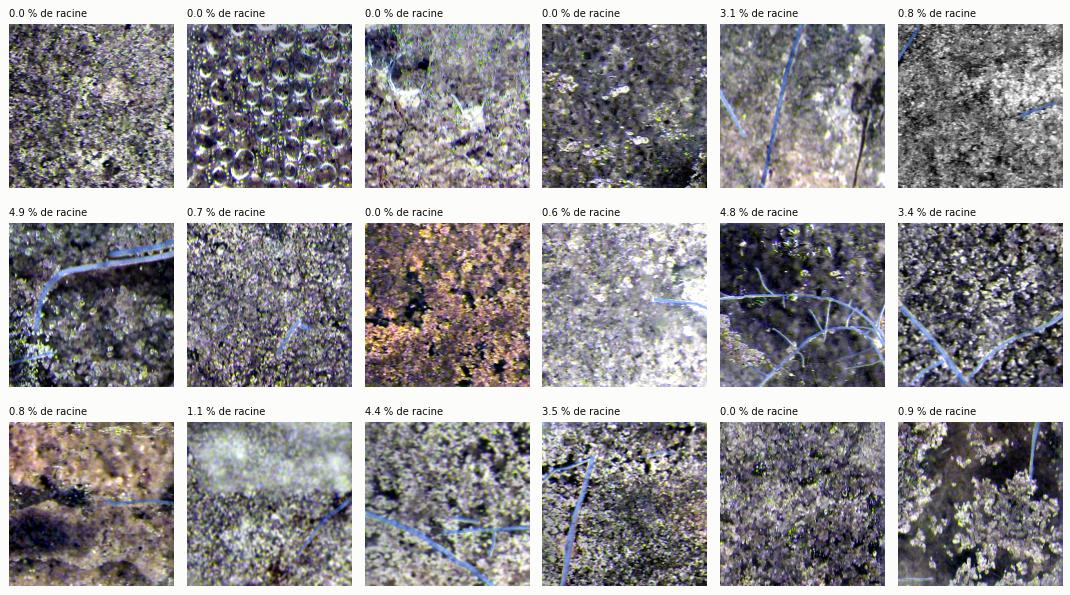

In [ ]:
crops = RootCrops(train_items, seed=1, augment=True, crops_per_epoch=CROPS_PER_EPOCH)
pairs = [crops[i] for i in range(18)]
images = [overlay_mask(to_display(x), y[0].numpy() > 0) for x, y in pairs]
viz.image_grid(images, [f'{y.mean() * 100:.1f} % de racine' for _, y in pairs], ncols=6);

## 2. Entraînement

Environ 1 h 50. Si l'entraînement existe déjà sous ce nom, il n'est pas relancé. En cas d'arrêt manuel, passer à la cellule suivante.

In [ ]:
if run_exists(NAME):
    print('Entraînement déjà présent, relecture de', NAME)
else:
    train(train_items, val_items, NAME, epochs=EPOCHS, patience=20, augment=True, crops_per_epoch=CROPS_PER_EPOCH,
          train_eval=train_eval_items(clean))   # mêmes 44 images corrigées que la référence

cpu, 926,521 paramètres utilisés, 1000 images train, 74 images val, 37 batchs par époque
  1/150  perte train 0.525  val 0.287  Dice train 0.504  val 0.465  global 0.560  racines 65%  fantômes 70  longueur 0.33  images vides touchées 0.40  lr 1.0e-04 / 1.0e-03  41 s
  2/150  perte train 0.385  val 0.194  Dice train 0.573  val 0.522  global 0.611  racines 70%  fantômes 104  longueur 0.25  images vides touchées 0.63  lr 1.0e-04 / 1.0e-03  40 s
  3/150  perte train 0.293  val 0.169  Dice train 0.584  val 0.558  global 0.632  racines 65%  fantômes 82  longueur 0.32  images vides touchées 0.43  lr 1.0e-04 / 1.0e-03  40 s
  4/150  perte train 0.271  val 0.165  Dice train 0.582  val 0.550  global 0.644  racines 66%  fantômes 43  longueur 0.37  images vides touchées 0.23  lr 1.0e-04 / 1.0e-03  40 s
  5/150  perte train 0.271  val 0.145  Dice train 0.623  val 0.619  global 0.675  racines 75%  fantômes 65  longueur 0.27  images vides touchées 0.47  lr 1.0e-04 / 1.0e-03  42 s
  6/150  perte train

KeyboardInterrupt: 

,epoch,lr,lr_encoder,train_loss,train_dice,dice,global_dice,roots_found,ghosts,length_err,fp_empty,val_loss,seconds
96,97,0.000288,0.000029,0.172875,0.735751,0.720687,0.762274,0.828571,34,0.119365,0.366667,0.105599,37.704215


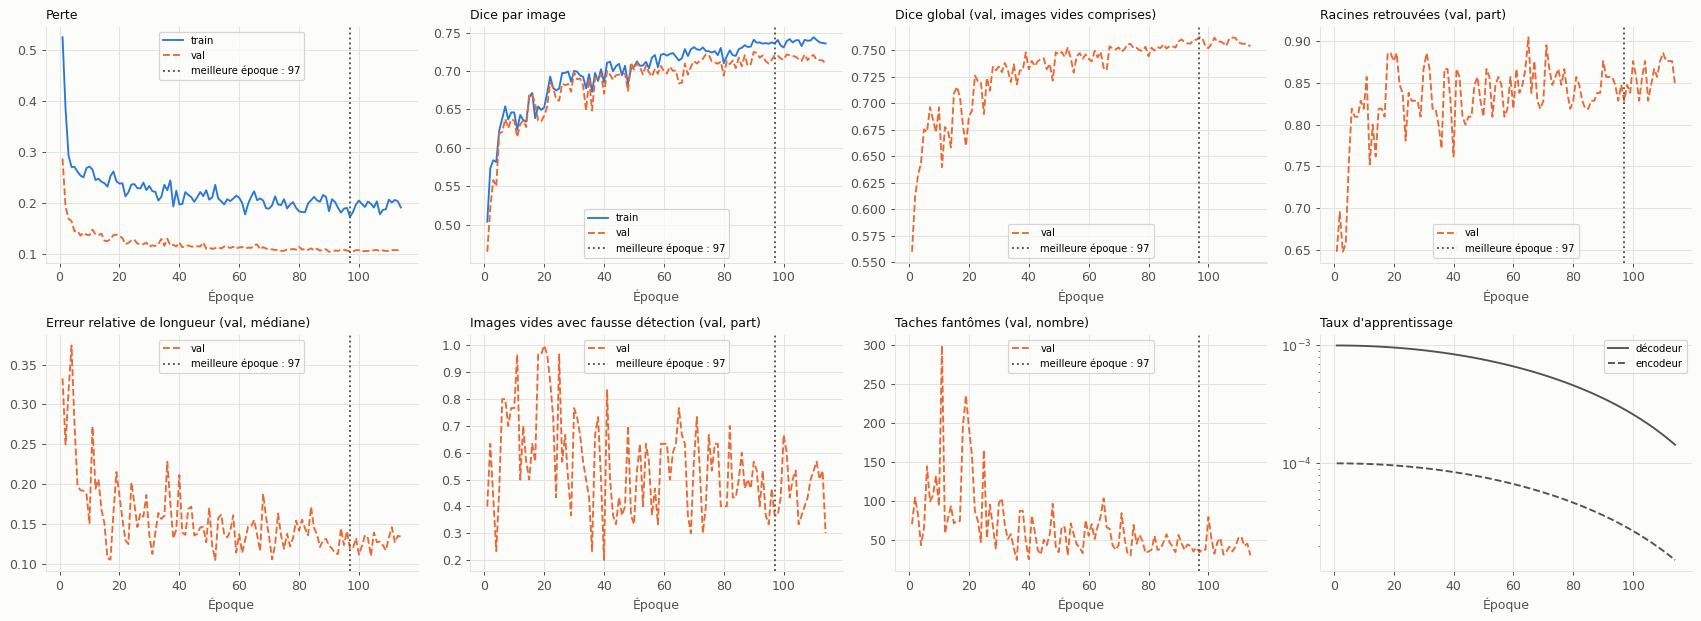

In [ ]:
model, history, best_epoch, per_image = load_run(NAME)
device = next(model.parameters()).device
viz.plot_history(history, best_epoch);
history.loc[history['epoch'] == best_epoch]

## 3. Comparaison avec la référence et avec E1

Moyennes du val à la meilleure époque de chaque essai, puis Dice image par image sur les 44 images du val avec racine (écart = 1 000 images moins l'autre essai ; positif : les 1 000 images font mieux).

In [ ]:
for other in (REFERENCE, ORIGINE):
    if not run_exists(other):
        print(other, ': essai absent')
        continue
    summary, paired, delta = compare_runs(other, NAME)
    print('\n1 000 images contre', other)
    display(summary.round(3))
    display(paired.round(4).to_frame('').T)


1 000 images contre unet_effb0_s2_aug


,epoch,train_dice,dice,global_dice,roots_found,ghosts,length_err,fp_empty
unet_effb0_s2_aug,82.0,0.814,0.703,0.763,0.838,39.0,0.150,0.400
unet_effb0_1000,97.0,0.736,0.721,0.762,0.829,34.0,0.119,0.367


,images,écart moyen,écart médian,b meilleur,b moins bon,p (Wilcoxon)
,44.0,0.018,0.0151,30.0,14.0,0.013



1 000 images contre unet_effb0_s2_aug_origine


,epoch,train_dice,dice,global_dice,roots_found,ghosts,length_err,fp_empty
unet_effb0_s2_aug_origine,47.0,0.741,0.678,0.751,0.800,24.0,0.184,0.200
unet_effb0_1000,97.0,0.736,0.721,0.762,0.829,34.0,0.119,0.367


,images,écart moyen,écart médian,b meilleur,b moins bon,p (Wilcoxon)
,44.0,0.0428,0.028,36.0,8.0,0.0012


Par type
                   dice       length_err      
                 median count     median count
type                                          
faible contraste  0.567     3      0.605     3
grise             0.595     3      0.477     3
orangée           0.801     3      0.018     3
saturée           0.722     4      0.302     4
sombre            0.805     4      0.080     4
typique           0.789    27      0.082    27

Par groupe
               dice       length_err      
             median count     median count
group                                     
150 BAZ 2015  0.787    19      0.082    19
150 BAZ 2016  0.740    15      0.123    15
150 CZ 2016   0.812    10      0.094    10


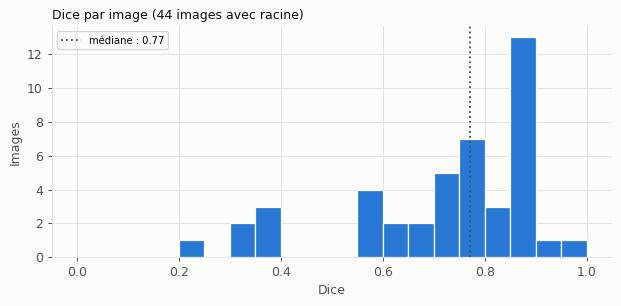

In [ ]:
viz.plot_dice(per_image);
rooted = per_image[per_image['has_root']]
print('Par type'); print(rooted.groupby('type')[['dice', 'length_err']].agg(['median', 'count']).round(3))
print('\nPar groupe'); print(rooted.groupby('group')[['dice', 'length_err']].agg(['median', 'count']).round(3))

## 4. Images

Toutes les images du val au curseur : référence corrigée à gauche, prédiction à droite, du plus bas Dice au plus haut, images sans racine à la fin.

In [ ]:
preds = {it['name']: predict(model, it, device) for it in val_items}
viz.browse_predictions(val_items, preds, per_image)

interactive(children=(IntSlider(value=0, continuous_update=False, description='Image', layout=Layout(width='80…

## 5. À retenir

- **Gain net** : Dice par image 0,72 contre 0,70 (notebook 03), Dice global inchangé (0,76) ; erreur de longueur en baisse (0,12 contre 0,15).
- **Surapprentissage presque supprimé** : Dice train 0,74, val 0,72.
- **Contre E1** (149 images PRMI) : +0,043 de Dice par image, 36 images sur 44 meilleures.
- **Suite** : tout le train, avec les fentes comblées (notebook A2, puis notebook 05).